In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.style
%matplotlib inline
import seaborn as sns; sns.set() # for plot styling
from scipy import stats
plt.rcParams['figure.figsize']=[15,8]
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import joblib
from sklearn.model_selection import RandomizedSearchCV
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram,linkage,fcluster
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_samples
from sklearn.metrics import silhouette_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn import metrics,model_selection
from sklearn.preprocessing import scale
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from xgboost import XGBRegressor
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import AdaBoostRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("/content/sample_data/rice_production_by_country.csv")

In [3]:
df.head()

,,Rice Production (Tons),Rank of Rice Production,Rice Production Per Person (Kg),Rank of Rice Production Per Person,Rice Acreage (Hectare),Rank of Rice Acreage,Rice Yield (Kg / Hectare),Rank of Rice Yield
0,Chile,174.9K,65.0,10,76,26.2K,77.0,"6,664.80",16.0
1,Mauritania,383.0K,50.0,96.1,26,73.0K,63.0,"5,249.20",36.0
2,Turkey,1.0M,40.0,12.4,68,126.4K,52.0,"7,910.20",7.0
3,Kyrgyzstan,41.2K,87.0,6.5,81,11.3K,89.0,"3,646.40",63.0
4,Laos,3.4M,21.0,493.9,3,783.8K,23.0,"4,386.50",49.0


In [4]:
df.tail()

,,Rice Production (Tons),Rank of Rice Production,Rice Production Per Person (Kg),Rank of Rice Production Per Person,Rice Acreage (Hectare),Rank of Rice Acreage,Rice Yield (Kg / Hectare),Rank of Rice Yield
114,Colombia,3.0M,24.0,60.3,39,531.2K,29.0,"5,671.20",30.0
115,Guatemala,42.0K,86.0,2.4,91,14.1K,84.0,"2,974.50",78.0
116,Peru,3.2M,23.0,102.1,24,414.5K,32.0,"7,691.80",8.0
117,DR Congo,1.4M,32.0,17,62,1.8M,13.0,760.3,111.0
118,Portugal,152.8K,70.0,14.8,65,28.5K,74.0,"5,359.60",34.0


In [7]:
df.replace(['Nna','N/A','N/A','n/a','N#A','n#a','?'],'other',inplace=True)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 9 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0                                       119 non-null    object 
 1   Rice Production (Tons)              119 non-null    object 
 2   Rank of Rice Production             118 non-null    float64
 3   Rice Production Per Person (Kg)     119 non-null    object 
 4   Rank of Rice Production Per Person  119 non-null    int64  
 5   Rice Acreage (Hectare)              119 non-null    object 
 6   Rank of Rice Acreage                118 non-null    float64
 7   Rice Yield (Kg / Hectare)           119 non-null    object 
 8   Rank of Rice Yield                  118 non-null    float64
dtypes: float64(3), int64(1), object(5)
memory usage: 8.5+ KB


In [9]:
df.shape

(119, 9)

In [10]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Rank of Rice Production,118.0,59.5,34.21,1.0,30.25,59.5,88.75,118.0
Rank of Rice Production Per Person,119.0,60.0,34.50,1.0,30.50,60.0,89.50,119.0
Rank of Rice Acreage,118.0,59.5,34.21,1.0,30.25,59.5,88.75,118.0
Rank of Rice Yield,118.0,59.5,34.21,1.0,30.25,59.5,88.75,118.0


In [11]:
df.describe(include="all").T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
,119,119,Chile,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rice Production (Tons),119,109,1.1M,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rank of Rice Production,118.0,NaN,NaN,NaN,59.5,34.207699,1.0,30.25,59.5,88.75,118.0
Rice Production Per Person (Kg),119,109,0.1,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rank of Rice Production Per Person,119.0,NaN,NaN,NaN,60.0,34.496377,1.0,30.5,60.0,89.5,119.0
Rice Acreage (Hectare),119,114,3.0M,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rank of Rice Acreage,118.0,NaN,NaN,NaN,59.5,34.207699,1.0,30.25,59.5,88.75,118.0
Rice Yield (Kg / Hectare),119,119,"6,664.80",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rank of Rice Yield,118.0,NaN,NaN,NaN,59.5,34.207699,1.0,30.25,59.5,88.75,118.0


In [12]:
numerical_vars = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_vars = df.select_dtypes(include=['object']).columns.tolist()
print('Numerical variables:', numerical_vars)
print('Categorical variables:', categorical_vars)

Numerical variables: ['Rank of Rice Production', 'Rank of Rice Production Per Person', 'Rank of Rice Acreage', 'Rank of Rice Yield']
Categorical variables: [' ', 'Rice Production (Tons)', 'Rice Production Per Person (Kg)', 'Rice Acreage (Hectare)', 'Rice Yield (Kg / Hectare)']


In [13]:
# Count the number of categorical and numerical variables
categorical_count = df.select_dtypes(include='object').shape[1]
numerical_count = df.select_dtypes(exclude='object').shape[1]

print(f"Number of categorical variables: {categorical_count}")
print(f"Number of numerical variables: {numerical_count}")

Number of categorical variables: 5
Number of numerical variables: 4


In [14]:
# Unique values for categorical features
print(df.select_dtypes(include=['object']).nunique())

                                   119
Rice Production (Tons)             109
Rice Production Per Person (Kg)    109
Rice Acreage (Hectare)             114
Rice Yield (Kg / Hectare)          119
dtype: int64


In [15]:
missing_df =  df.isnull().sum().to_frame().rename(columns={0:"Total No. of Missing Values"})
missing_df["% of Missing Values"] = round((missing_df["Total No. of Missing Values"]/len( df))*100,2)
missing_df

,Total No. of Missing Values,% of Missing Values
,0,0.00
Rice Production (Tons),0,0.00
Rank of Rice Production,1,0.84
Rice Production Per Person (Kg),0,0.00
Rank of Rice Production Per Person,0,0.00
Rice Acreage (Hectare),0,0.00
Rank of Rice Acreage,1,0.84
Rice Yield (Kg / Hectare),0,0.00
Rank of Rice Yield,1,0.84


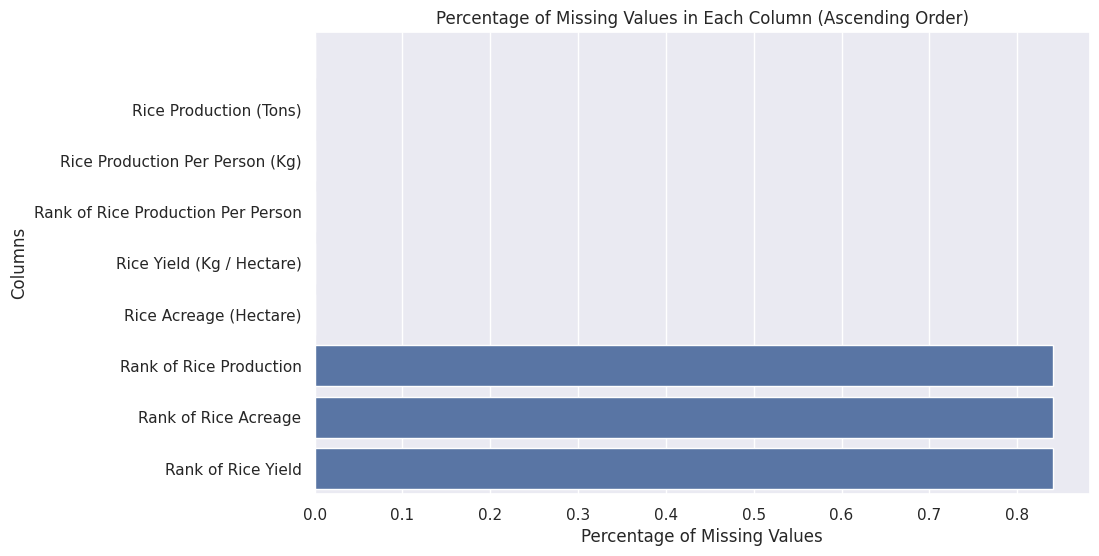

In [16]:
# Calculate the percentage of missing values for each column
missing_values_percentage = df.isnull().mean() * 100

# Now you can sort and visualize the missing values
missing_values_percentage_sorted = missing_values_percentage.sort_values()

# Visualization code
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x=missing_values_percentage_sorted, y=missing_values_percentage_sorted.index)
plt.title('Percentage of Missing Values in Each Column (Ascending Order)')
plt.xlabel('Percentage of Missing Values')
plt.ylabel('Columns')
plt.show()

<Axes: >

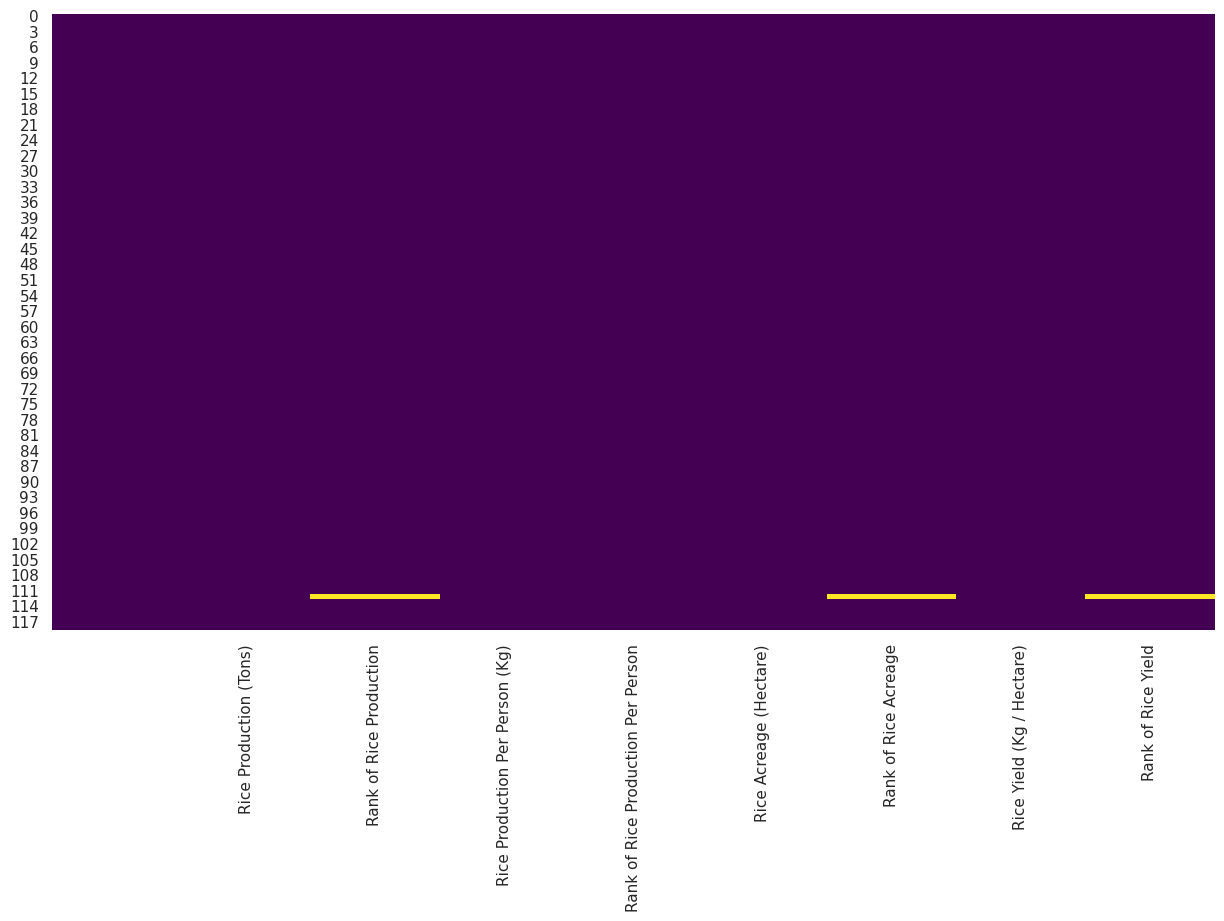

In [17]:
sns.heatmap(df.isnull(),cbar=False,cmap='viridis')

In [18]:
# Handling missing values
# Imputing missing values with the mean for continuous variables and mode for categorical variables
for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].mean(), inplace=True)

# Checking for missing values before imputation
missing_values = df.isnull().sum()

# Rechecking for missing values after imputation
missing_values_after = df.isnull().sum()

(missing_values, missing_values_after)

(                                      0
 Rice Production (Tons)                0
 Rank of Rice Production               0
 Rice Production Per Person (Kg)       0
 Rank of Rice Production Per Person    0
 Rice Acreage (Hectare)                0
 Rank of Rice Acreage                  0
 Rice Yield (Kg / Hectare)             0
 Rank of Rice Yield                    0
 dtype: int64,
                                       0
 Rice Production (Tons)                0
 Rank of Rice Production               0
 Rice Production Per Person (Kg)       0
 Rank of Rice Production Per Person    0
 Rice Acreage (Hectare)                0
 Rank of Rice Acreage                  0
 Rice Yield (Kg / Hectare)             0
 Rank of Rice Yield                    0
 dtype: int64)

In [19]:
missing_df =  df.isnull().sum().to_frame().rename(columns={0:"Total No. of Missing Values"})
missing_df["% of Missing Values"] = round((missing_df["Total No. of Missing Values"]/len( df))*100,2)
missing_df

,Total No. of Missing Values,% of Missing Values
,0,0.0
Rice Production (Tons),0,0.0
Rank of Rice Production,0,0.0
Rice Production Per Person (Kg),0,0.0
Rank of Rice Production Per Person,0,0.0
Rice Acreage (Hectare),0,0.0
Rank of Rice Acreage,0,0.0
Rice Yield (Kg / Hectare),0,0.0
Rank of Rice Yield,0,0.0


In [20]:
df[df.duplicated(keep=False)]

,,Rice Production (Tons),Rank of Rice Production,Rice Production Per Person (Kg),Rank of Rice Production Per Person,Rice Acreage (Hectare),Rank of Rice Acreage,Rice Yield (Kg / Hectare),Rank of Rice Yield


In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
# Drop duplicate rows from the DataFrame
df.drop_duplicates(inplace=True)

In [23]:
df.shape

(119, 9)

In [24]:
# Get the list of categorical columns
cat_cols = df.select_dtypes(include='object').columns.tolist()

# Create a DataFrame containing counts of unique values for each categorical column
cat_df = pd.DataFrame(df[cat_cols].melt(var_name='column', value_name='value')
                      .value_counts()).rename(columns={0: 'count'}).sort_values(by=['column', 'count'])

# Display summary statistics of categorical variables
display(df[cat_cols].describe())

# Display counts of unique values for each categorical column
display(cat_df)

,,Rice Production (Tons),Rice Production Per Person (Kg),Rice Acreage (Hectare),Rice Yield (Kg / Hectare)
count,119,119,119,119,119
unique,119,109,109,114,119
top,Chile,1.1M,0.1,3.0M,"6,664.80"
freq,1,5,3,2,1


count
column                    value              
                          Costa Rica        1
                          Belize            1
                          Saudi Arabia      1
                          Senegal           1
                          Sierra Leone      1
...                                       ...
Rice Yield (Kg / Hectare) 2,842.50          1
                          2,101.00          1
                          8,771.00          1
                          6,836.30          1
                          6,826.80          1

[570 rows x 1 columns]

In [25]:
df.describe(include='O').T

,count,unique,top,freq
,119,119,Chile,1
Rice Production (Tons),119,109,1.1M,5
Rice Production Per Person (Kg),119,109,0.1,3
Rice Acreage (Hectare),119,114,3.0M,2
Rice Yield (Kg / Hectare),119,119,"6,664.80",1


In [26]:
# Inspect useless features
df.nunique().sort_values()

,0
Rice Production (Tons),109
Rice Production Per Person (Kg),109
Rice Acreage (Hectare),114
,119
Rank of Rice Production,119
Rank of Rice Production Per Person,119
Rank of Rice Acreage,119
Rice Yield (Kg / Hectare),119
Rank of Rice Yield,119


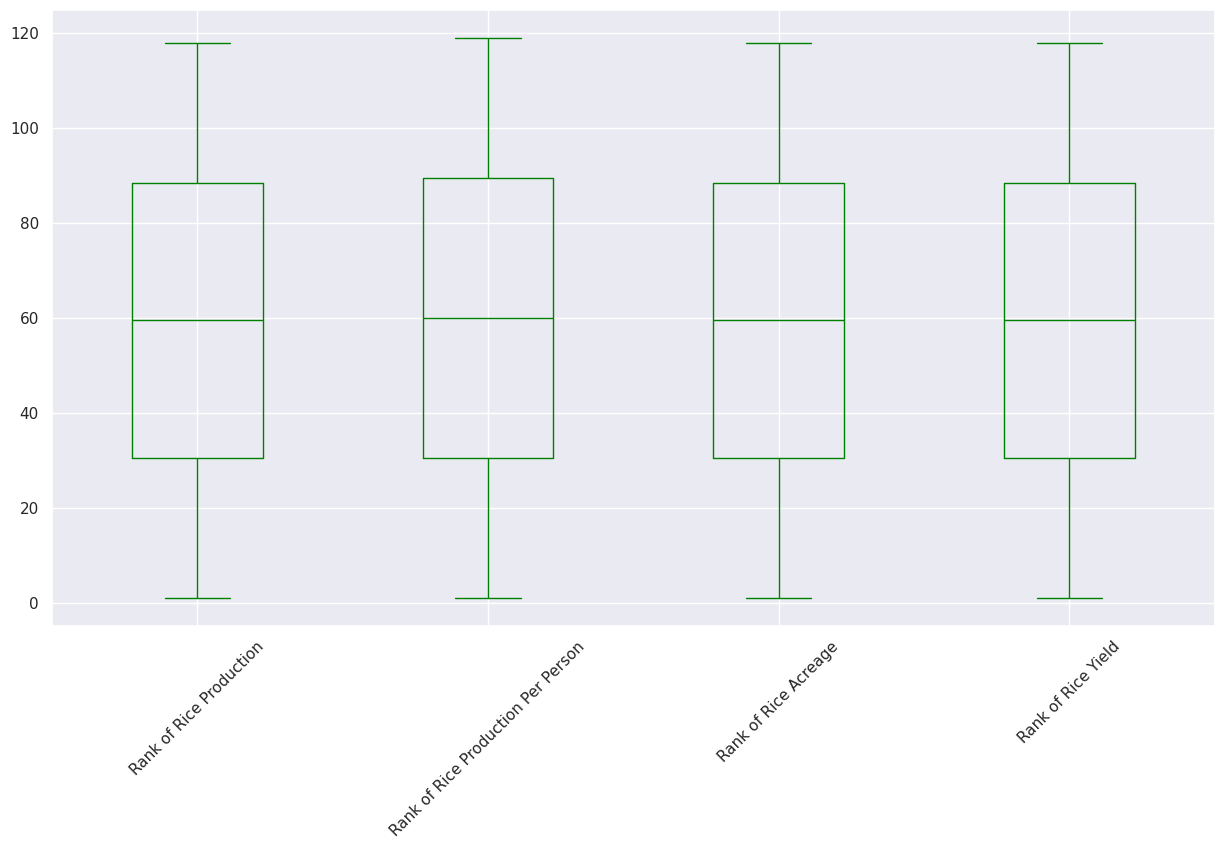

In [27]:
# Plot the boxplot with rotated text labels
df.plot(kind='box', rot=45,color='green')

# Show the plot
plt.show()

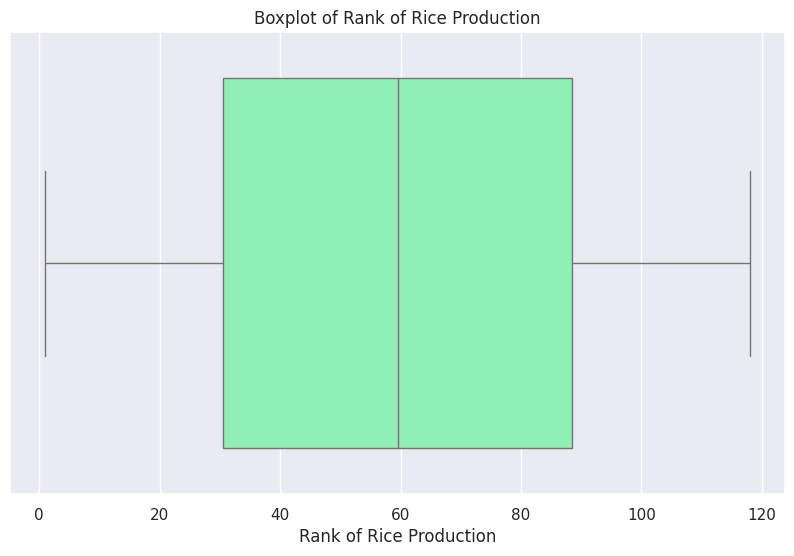

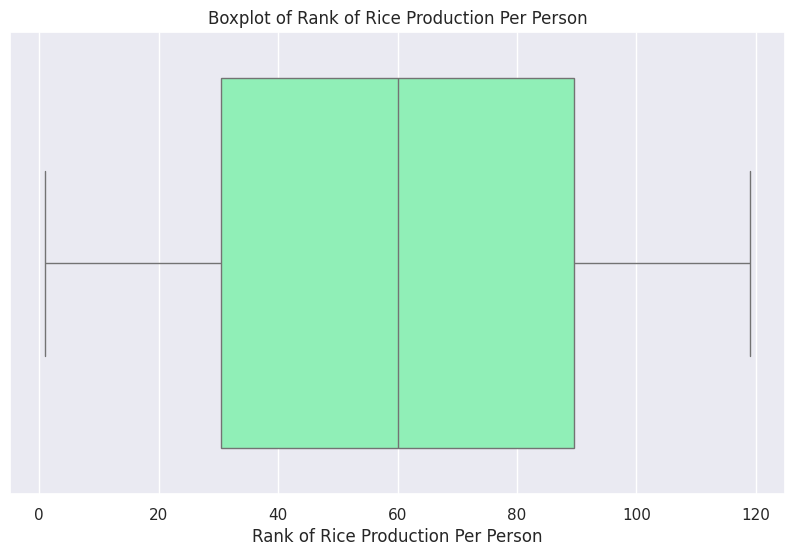

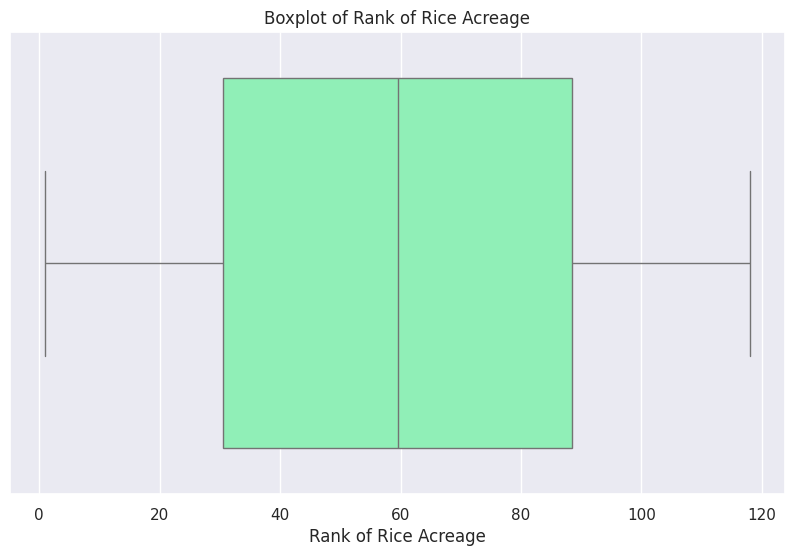

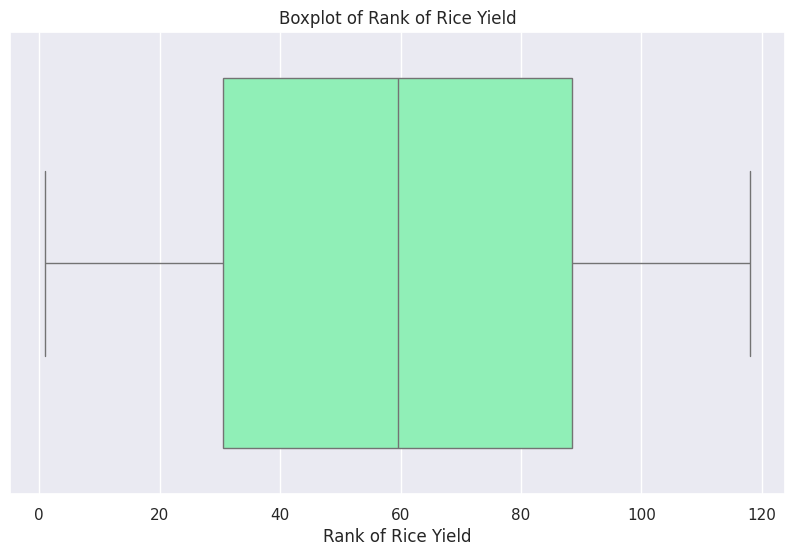

In [28]:
# Filter numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Plotting boxplots for each numerical feature to identify outliers
for column in numeric_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[column],palette='rainbow')
    plt.title(f'Boxplot of {column}')
    plt.show()

Text(0.5, 1.0, 'Correlation Matrix')

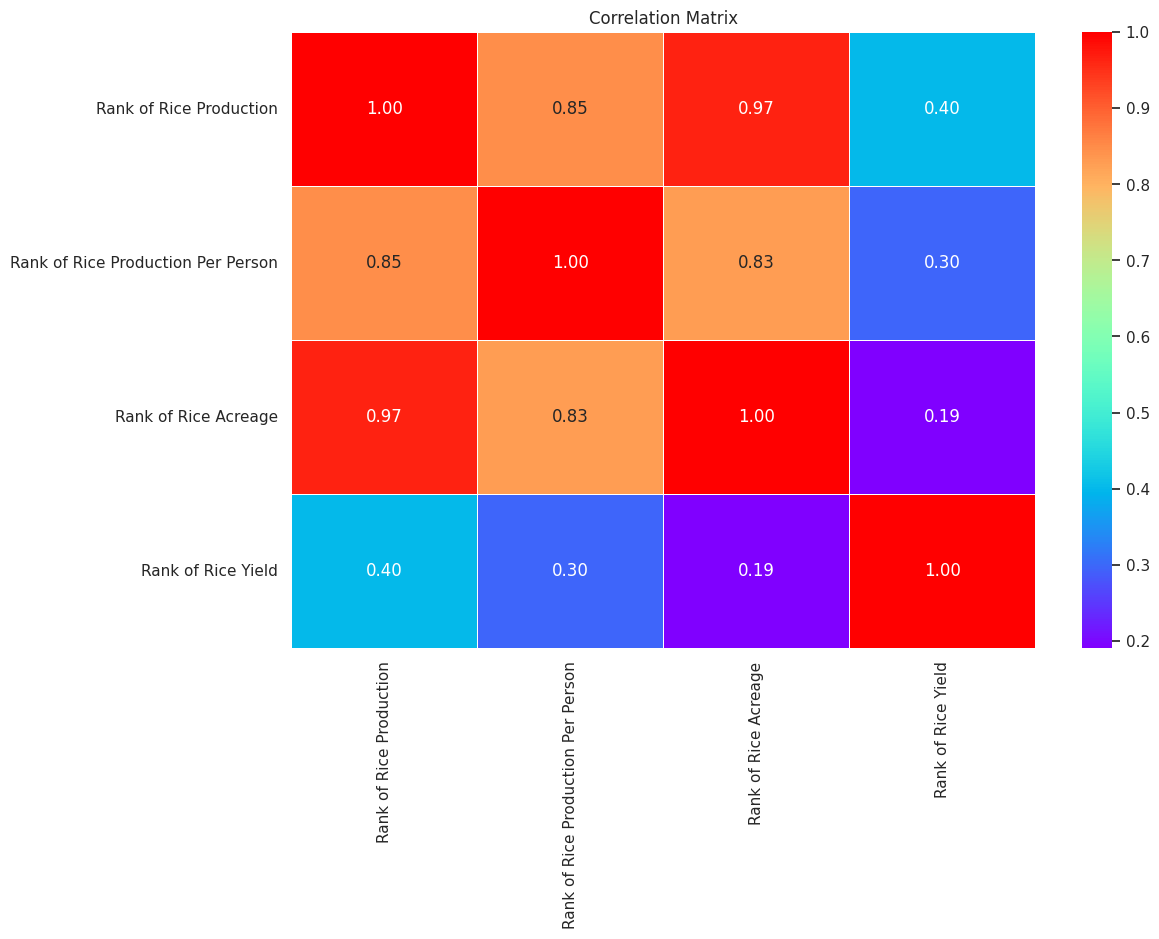

In [29]:
# Correlation matrix

# Select only the numeric columns from the DataFrame
numeric_columns = df.select_dtypes(include=['number'])

# Calculate the correlation matrix
correlation_matrix = numeric_columns.corr()

# Create a heatmap to visualize the correlations
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='rainbow', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')

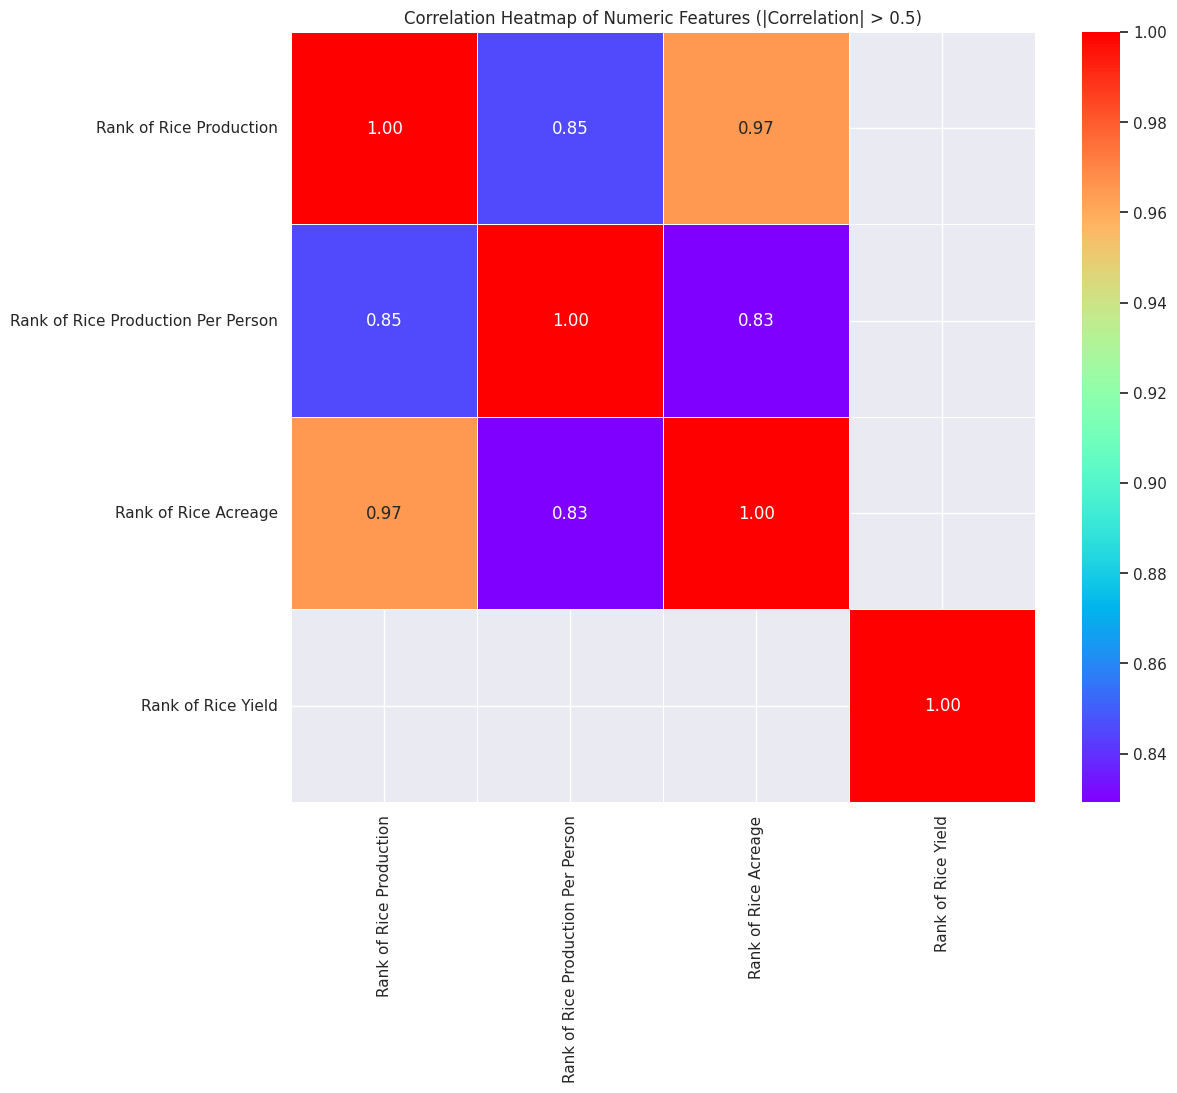

In [30]:
# Heatmap Plotting
# Select only numeric columns
numeric_columns = df.select_dtypes(include=['int64', 'float64'])

# Calculate the correlation matrix
corr_matrix = numeric_columns.corr()

# Filter correlation matrix to include values greater than 0.5 or less than -0.5
corr_matrix_filtered = corr_matrix[(corr_matrix > 0.5) | (corr_matrix < -0.5)]

# Plot the heatmap with filtered correlation values
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_filtered, annot=True, cmap='rainbow', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features (|Correlation| > 0.5)')
plt.show()

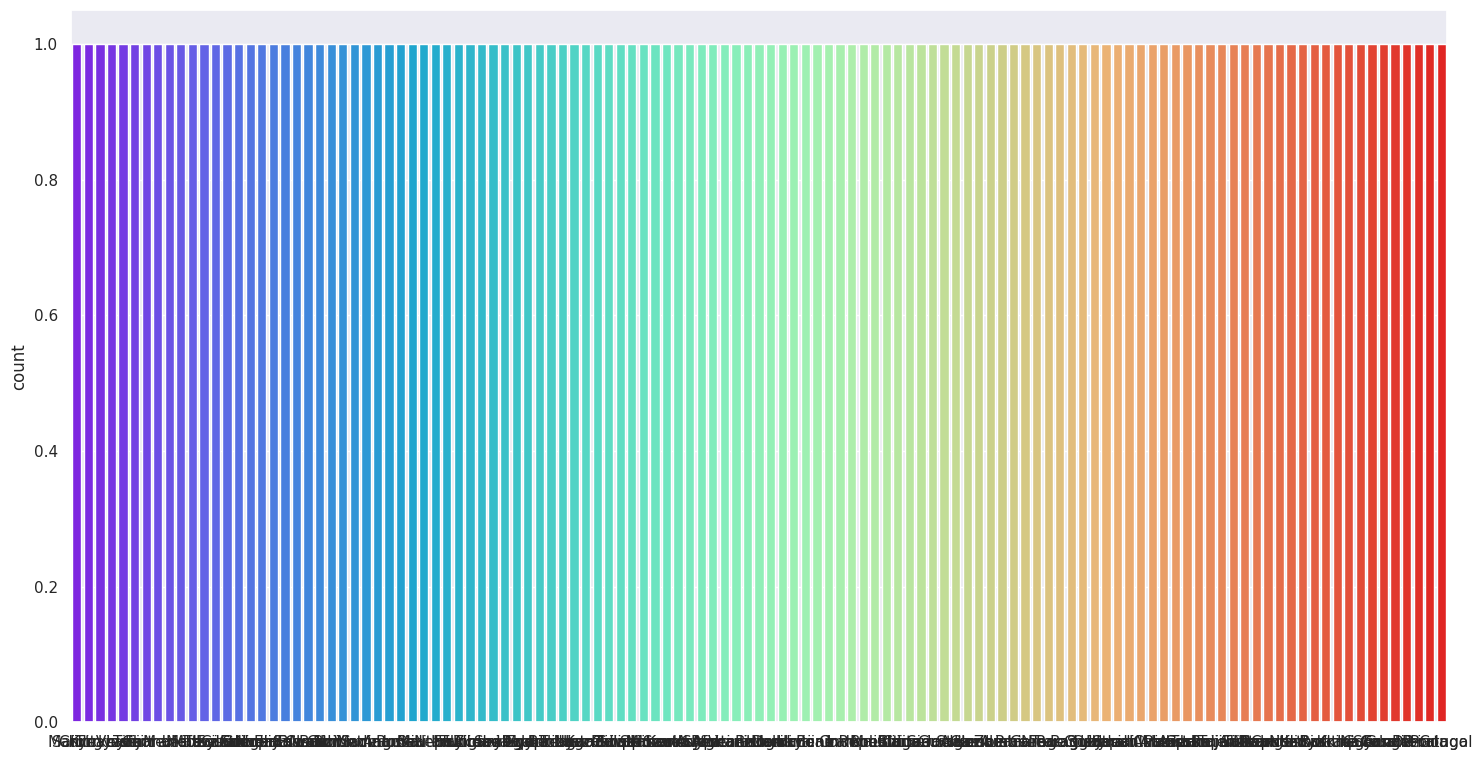

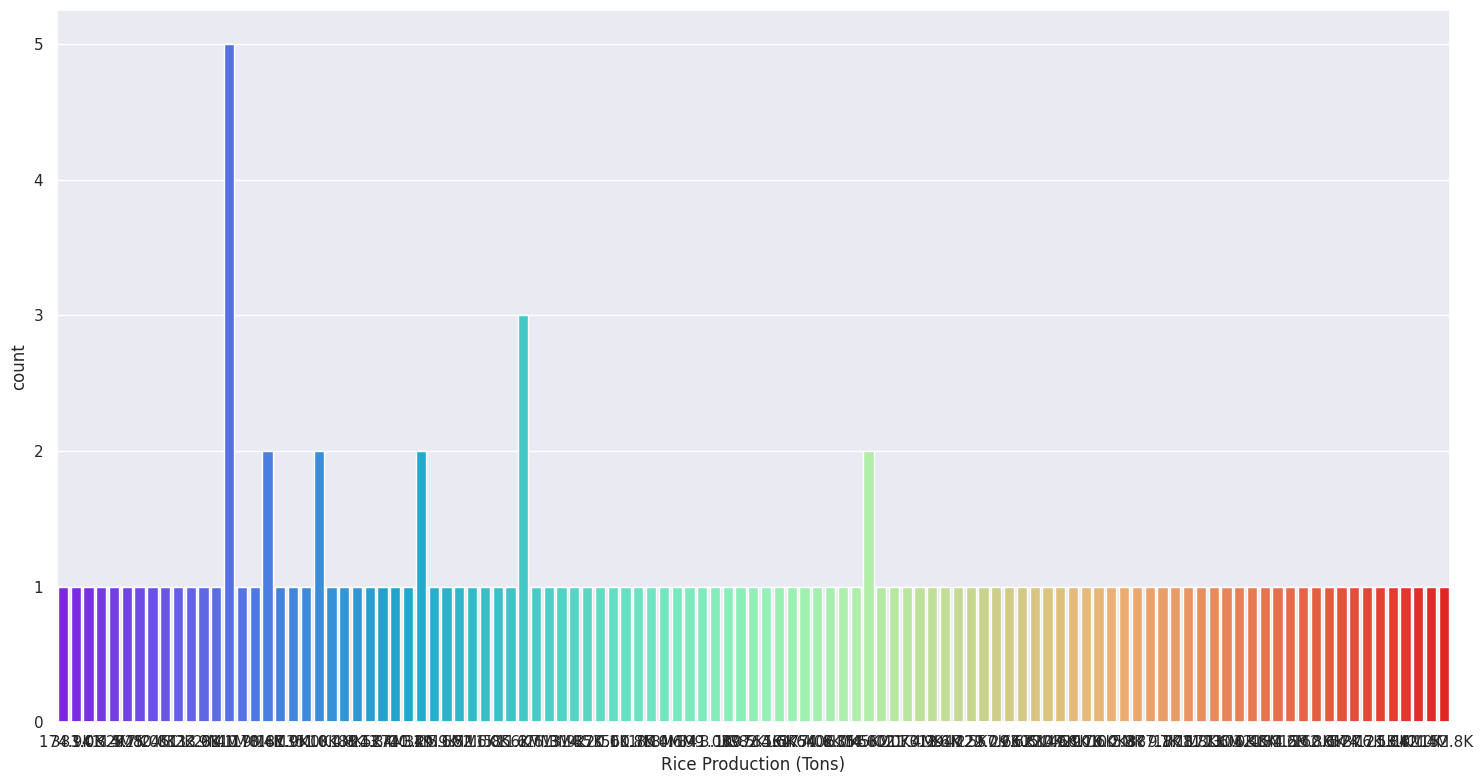

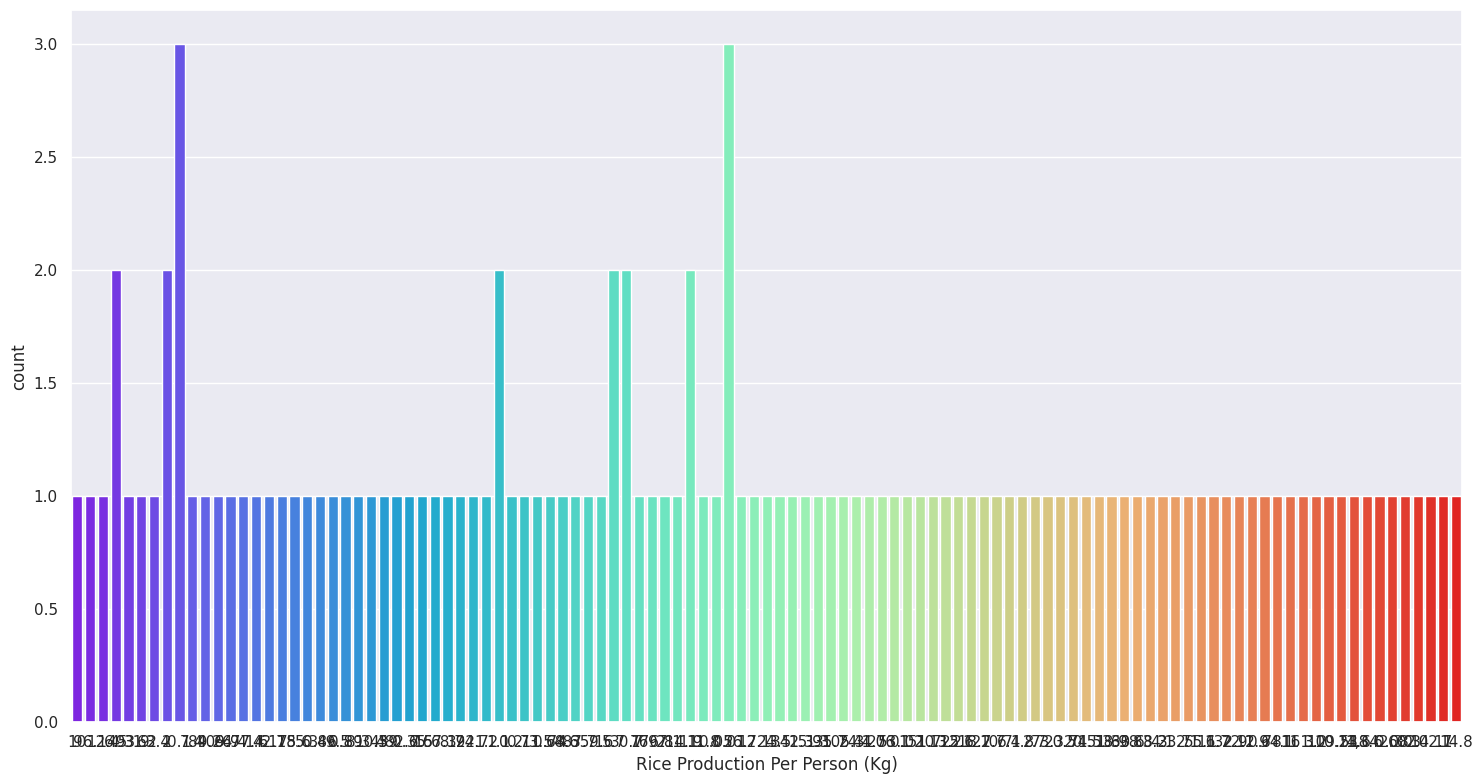

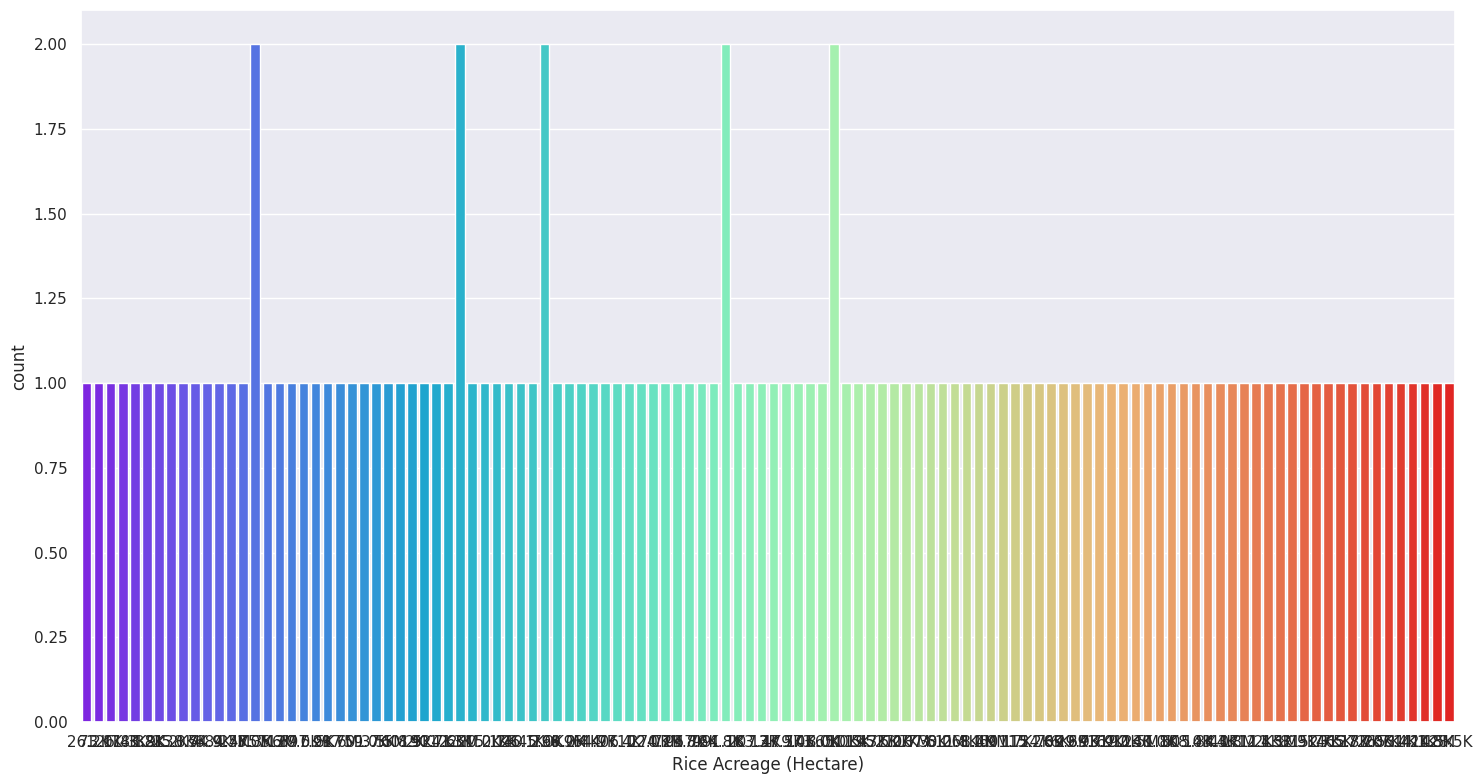

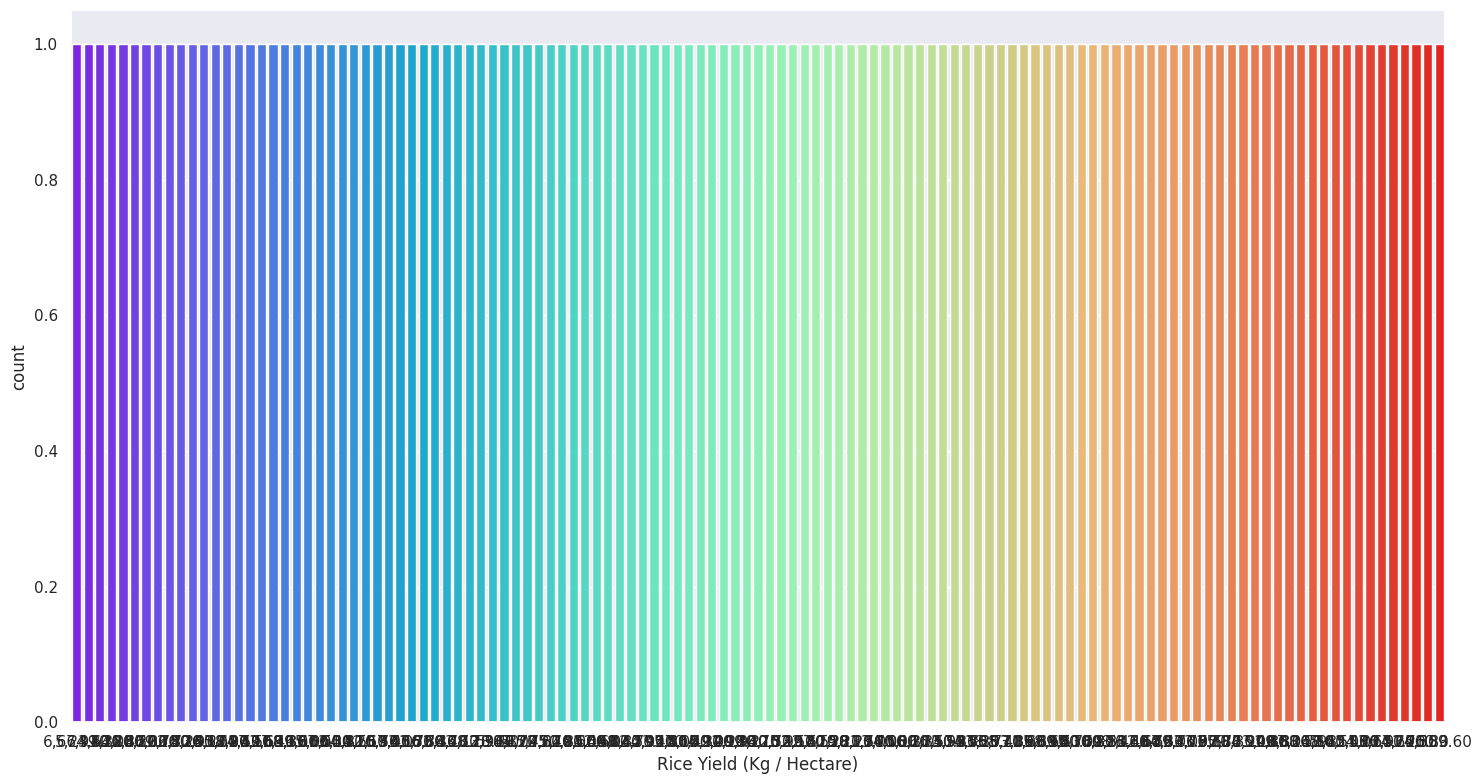

In [31]:
# Explore categorical features
for column in df.select_dtypes(include=['object']):
    sns.countplot(x=column, data=df,palette='rainbow')
    plt.tight_layout()
    plt.show()

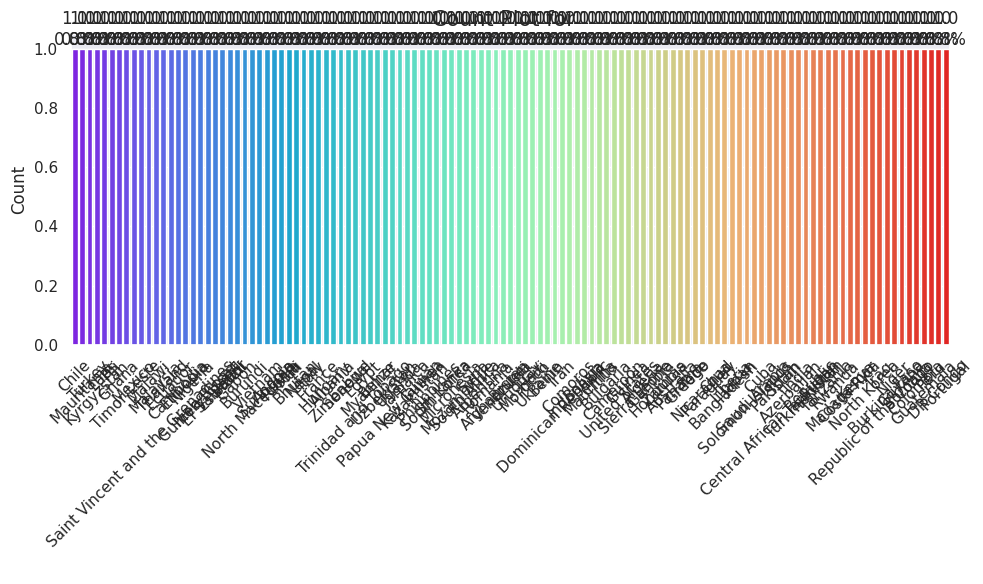

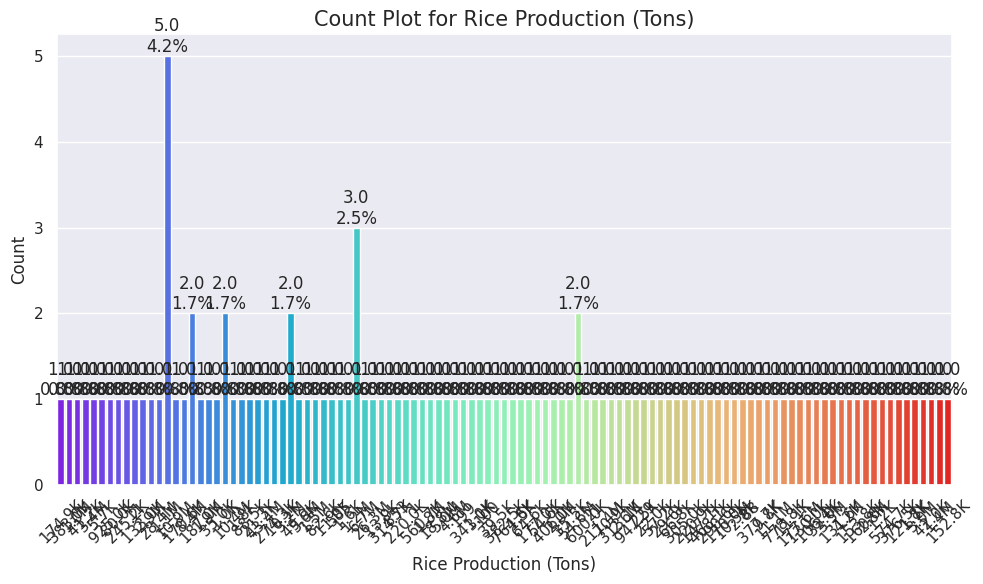

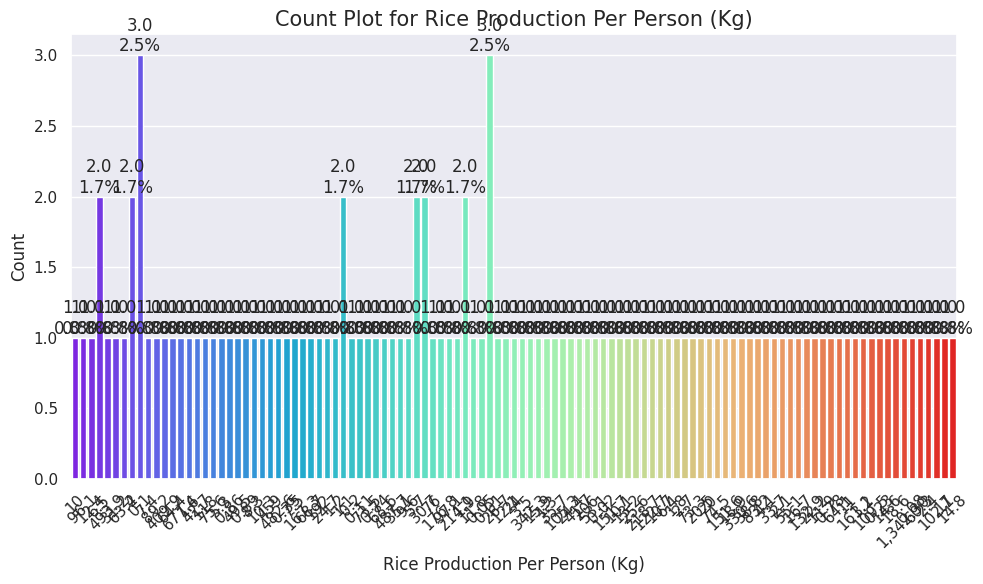

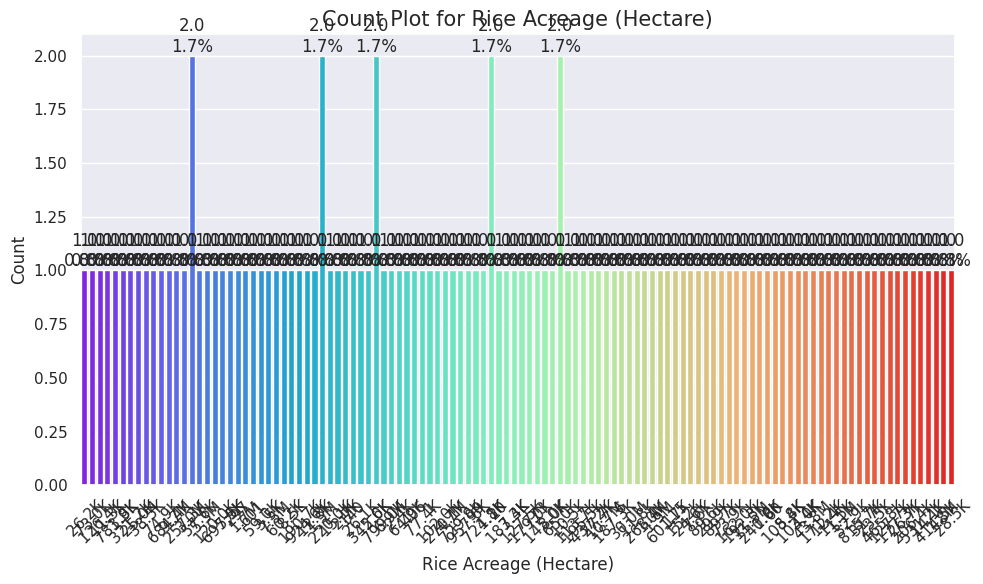

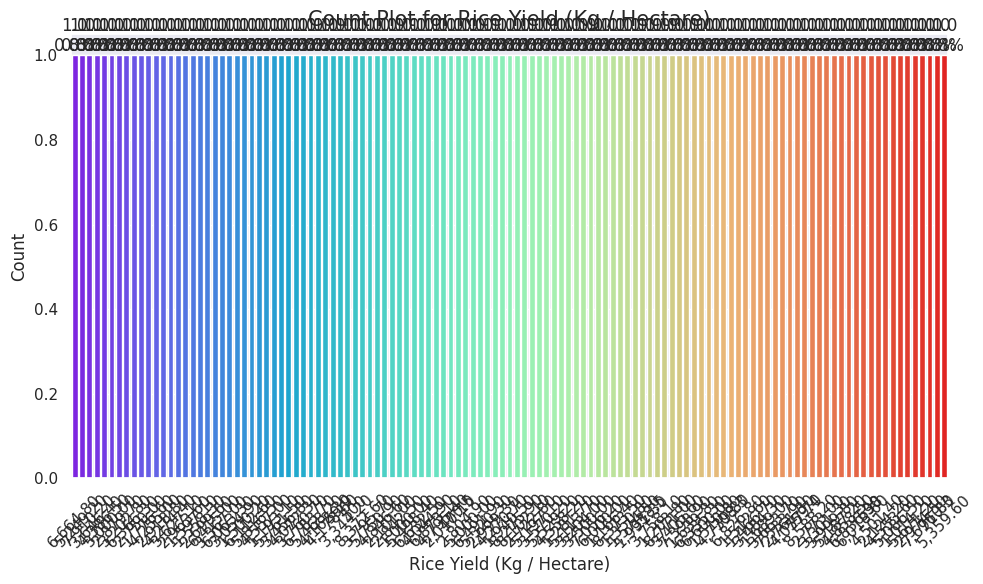

In [32]:
# Explore categorical features
for column in df.select_dtypes(include=['object']):
    plt.figure(figsize=(10, 6))
    ax = sns.countplot(x=column, data=df,palette='rainbow')

    # Add count and percentage annotations to each bar
    total = len(df[column])
    for p in ax.patches:
        percentage = '{:.1f}%'.format(100 * p.get_height() / total)
        count = p.get_height()
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(f'{count}\n{percentage}', (x, y), ha='center', va='bottom')

    plt.title(f'Count Plot for {column}', fontsize=15)
    plt.xlabel(column, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
    plt.tight_layout()
    plt.show()

In [33]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Sample DataFrame (replace this with your actual DataFrame)
# df = ...

# Function to remove outliers using the IQR method
def remove_outliers_iqr(df):
    # Select only numeric columns
    numeric_df = df.select_dtypes(include=['int64', 'float64'])

    # Calculate the first quartile (Q1) and third quartile (Q3)
    Q1 = numeric_df.quantile(0.25)
    Q3 = numeric_df.quantile(0.75)

    # Interquartile range (IQR)
    IQR = Q3 - Q1

    # Define the lower and upper bounds for outlier detection
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = ((numeric_df < lower_bound) | (numeric_df > upper_bound)).any(axis=1)

    # Count the number of outliers removed
    num_outliers_removed = outliers.sum()

    # Filter DataFrame based on rows without outliers
    df_no_outliers = df[~outliers]

    return df_no_outliers, num_outliers_removed

# Remove outliers using IQR method and get the number of outliers removed
df_no_outliers, num_outliers_removed = remove_outliers_iqr(df)

print("Number of outliers removed:", num_outliers_removed)

# Function to plot boxplots before and after removing outliers
def plot_boxplots_before_after(df_before, df_after):
    # Set up the figure
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

    # Boxplot before removing outliers (blue color)
    sns.boxplot(data=df_before, ax=axes[0], color='blue')
    axes[0].set_title('Before Removing Outliers')

    # Boxplot after removing outliers (green color)
    sns.boxplot(data=df_after, ax=axes[1], color='green')
    axes[1].set_title('After Removing Outliers')

    # Adjust layout
    plt.tight_layout()
    plt.show()


Number of outliers removed: 0


In [34]:
catcol = []
numcol = []

for col in df.columns:
    if df[col].dtype == 'object':
        catcol.append(col)
    else:
        numcol.append(col)

In [35]:
print("Categorical Columns:",catcol)
print("Numerical Columns:", numcol)

Categorical Columns: [' ', 'Rice Production (Tons)', 'Rice Production Per Person (Kg)', 'Rice Acreage (Hectare)', 'Rice Yield (Kg / Hectare)']
Numerical Columns: ['Rank of Rice Production', 'Rank of Rice Production Per Person', 'Rank of Rice Acreage', 'Rank of Rice Yield']


In [36]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

for col in catcol:
    df[col] = encoder.fit_transform(df[col])

In [37]:
from sklearn.preprocessing import MinMaxScaler

scale = MinMaxScaler()

for col in numcol:
    df[[col]] = scale.fit_transform(df[[col]])

In [38]:
df.head()

,,Rice Production (Tons),Rank of Rice Production,Rice Production Per Person (Kg),Rank of Rice Production Per Person,Rice Acreage (Hectare),Rank of Rice Acreage,Rice Yield (Kg / Hectare),Rank of Rice Yield
0,21,21,0.547009,20,0.635593,41,0.649573,100,0.128205
1,64,44,0.418803,107,0.211864,73,0.529915,77,0.299145
2,108,69,0.333333,32,0.567797,14,0.435897,109,0.051282
3,57,47,0.735043,88,0.677966,7,0.752137,47,0.529915
4,58,96,0.170940,82,0.016949,77,0.188034,62,0.410256


In [39]:
x = df.drop('Rice Yield (Kg / Hectare)',axis=1)
y = df['Rice Yield (Kg / Hectare)']

In [40]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.15,shuffle = True,random_state=42)

In [41]:
# Print the shapes of the resulting sets
print("Training set shape:", x_train.shape, y_train.shape)
print("Testing set shape:", x_test.shape, y_test.shape)

Training set shape: (101, 8) (101,)
Testing set shape: (18, 8) (18,)


In [42]:
def evaluate_model(true,predicted):
    mse = mean_squared_error(true, predicted)
    mae = mean_absolute_error(true,predicted)
    rmse = np.sqrt(mse)
    r2_square = r2_score(true,predicted)
    return mae,rmse,r2_square

In [43]:
models = {
            "Linear Regression" : LinearRegression(),
            "Lasso" : Lasso(),
            "Ridge" : Ridge(),
            "k-Neighbors Regression" : KNeighborsRegressor(),
            "Decision Tree" : DecisionTreeRegressor(),
            "Random Forest Regressor" : RandomForestRegressor(n_estimators = 100, random_state = 0),
            "AdaBoost Regressor" :AdaBoostRegressor(),
            "XGBRegressor" : XGBRegressor()
        }

In [44]:
score_text=""
for i in range(len(models)):
            model = list(models.values())[i]
            model.fit(x_train,y_train)

            #Make prediction:
            y_train_pred = model.predict(x_train)
            y_test_pred = model.predict(x_test)

            #Evaluate Train and Test dataset :

            model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
            model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)
            model_name = list(models.keys())[i]

            print(model_name)

            print("Model Performance for Training set :")

            print('Root Mean Squared Error :',model_train_rmse)
            print("Mean Absolute Error : ", model_train_mae)
            print("R2 Score : ", model_train_r2)

            print("----------------------------------------------------")

            print("Model Performance for Testing set :")

            print('Root Mean Squared Error : ', model_test_rmse)
            print('Mean Absolute Error :  ',{model_test_mae})
            print('R2 Score : ', {model_test_r2})
            print()


Linear Regression
Model Performance for Training set :
Root Mean Squared Error : 15.880991119189146
Mean Absolute Error :  9.940126627485597
R2 Score :  0.7838538503813607
----------------------------------------------------
Model Performance for Testing set :
Root Mean Squared Error :  27.763226307587995
Mean Absolute Error :   {15.497093493945052}
R2 Score :  {0.37667222723390015}

Lasso
Model Performance for Training set :
Root Mean Squared Error : 19.03451557557379
Mean Absolute Error :  13.46950311190663
R2 Score :  0.6894897399754008
----------------------------------------------------
Model Performance for Testing set :
Root Mean Squared Error :  33.31696843185181
Mean Absolute Error :   {18.952503391024777}
R2 Score :  {0.10234890316947753}

Ridge
Model Performance for Training set :
Root Mean Squared Error : 18.47432718314665
Mean Absolute Error :  12.917186220276326
R2 Score :  0.7074975155132464
----------------------------------------------------
Model Performance for Testi